# Connect to system

In [1]:
from py4lexis.session import LexisSession
from qaas.client import QProvider, QBackend, QJob


# 1. Authentication
lexis_session = LexisSession()
token = lexis_session.get_access_token()


# 2. Configure resources
PROJECT = "OPEN-37-13"
RESOURCE = "VLQ-CZ"

# 3. Initialize QaaS
provider = QProvider(PROJECT,token)
backend:QBackend = provider.get_backend(RESOURCE)


Welcome to the Py4LEXIS (v7.1.0)!
Proceeding login via login page...
Open provided url in your browser, please: https:/aai.lexis.tech/auth/realms/LEXIS_AAI_v2/protocol/openid-connect/auth/device?user_code=FLHQ-KPZP


Gtk-Message: 13:54:57.032: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.


Check if user is logged in: Pending.                                            
Check if user is logged in: OK!
You have been successfully logged in LEXIS session.


/home/broum/miniconda3/envs/vlq/lib/python3.12/site-packages/qaas/client/client.py:270: UserWarning: Patch Version Mismatch: recommending update. expected v0.5.x but server returned v0.5.x (expected=0.5.0, actual=0.5.3).
  warnings.warn(


# Prepare circuit

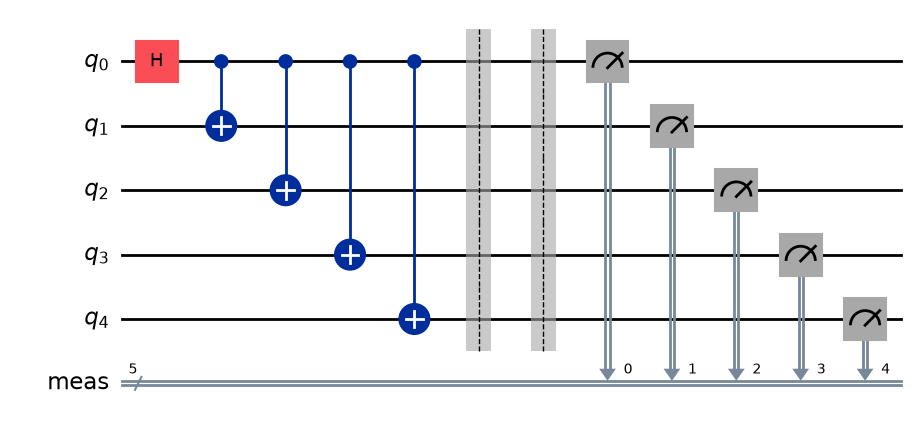

In [7]:
from qiskit import QuantumCircuit

# Define quantum circuit
num_qb = 5
qc = QuantumCircuit(num_qb)
qc.h(0)
for qb in range(1, num_qb):
    qc.cx(0, qb)

qc.barrier()
qc.measure_all()

qc.draw('mpl')

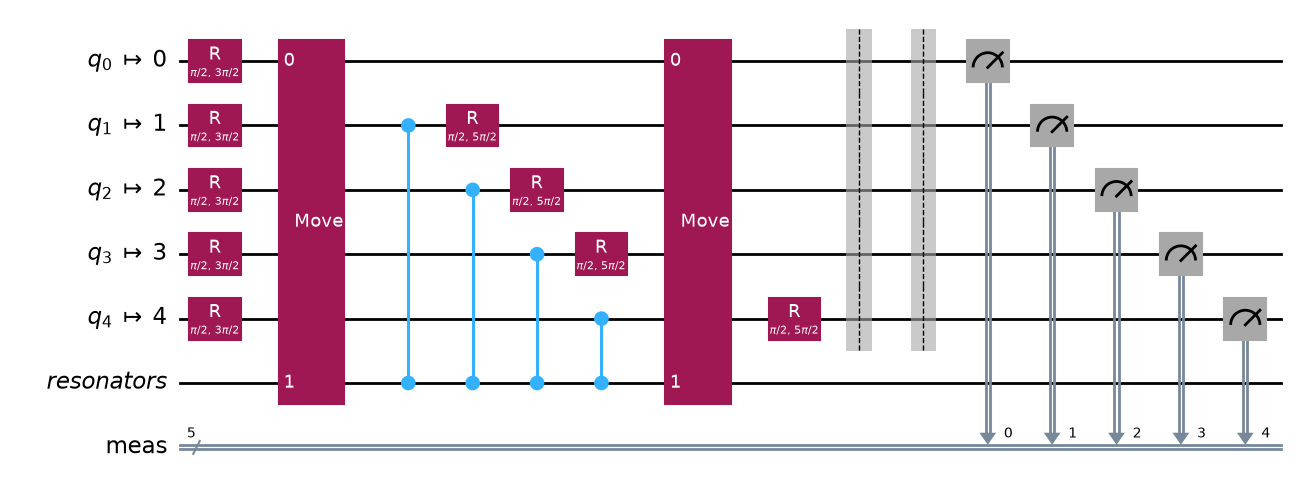

In [5]:
from iqm.qiskit_iqm import  transpile_to_IQM

# Transpile circuit
qc_transpiled = transpile_to_IQM(qc, backend)
qc_transpiled.draw('mpl')

# Run circuit

{'00000': 2225, '11111': 1845, '11011': 104, '10000': 46, '00001': 27, '10010': 1, '00101': 2, '01111': 110, '00111': 15, '10111': 121, '11110': 112, '01110': 19, '11101': 105, '00100': 48, '01000': 47, '00010': 65, '11010': 9, '00110': 27, '11100': 5, '01101': 7, '10101': 5, '01100': 6, '11001': 7, '10110': 10, '00011': 2, '01010': 4, '10011': 8, '01011': 6, '01001': 3, '10100': 3, '10001': 3, '11000': 3}


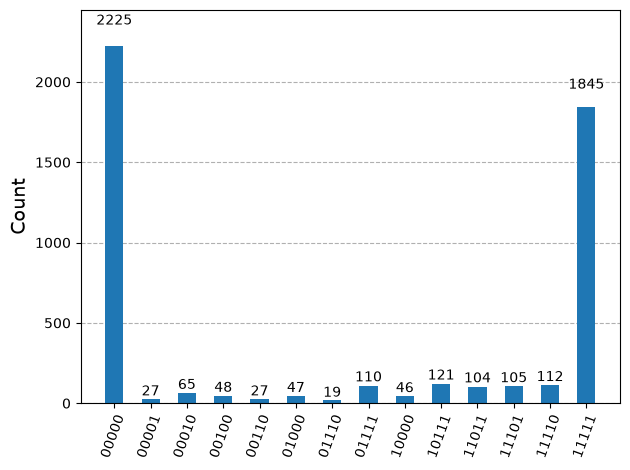

In [6]:
from qiskit.visualization import plot_histogram

# Run circuit
SHOTS = 5000

job = backend.run(qc_transpiled, shots=SHOTS)
results = job.result().get_counts()


# Plot result
print(results)

result_clean = {key: count for key, count in results.items() if count > 15}
display(plot_histogram(result_clean))